# Controlled MolMIM with Custom Oracle - QSAR 01

In [1]:
#!pip install cma matplotlib numpy pandas rdkit

In [2]:
#!pip install msal

In [3]:
import cma
import json
import matplotlib.pyplot as plt
import numpy as np
import requests
from IPython.display import display, clear_output
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.QED import qed
from rdkit.Chem.Crippen import MolLogP
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.DataStructs import TanimotoSimilarity
from rdkit import RDLogger                                                                                                                                                               
RDLogger.DisableLog('rdApp.*')

### Define the NIM host
To get started, we'll define our NIM host and the NIM endpoints we'll use in the following cells.

 - `/sampling` - Perform random sampling around a seed SMILES to define a starting population
 - `/hidden` - Generate the hidden state encoding for a set of input SMILES
 - `/decode` - Decode hidden state encodings to return a set of SMILES

In [4]:
!docker ps -a
# In case you want to stop the container -> !docker stop molmim

CONTAINER ID   IMAGE                                                       COMMAND                  CREATED             STATUS             PORTS                                                           NAMES
b5dc763091be   841162696343.dkr.ecr.us-east-1.amazonaws.com/molmim:1.0.0   "/opt/nvidia/nvidia_…"   About an hour ago   Up About an hour   6006/tcp, 8888/tcp, 0.0.0.0:8080->8000/tcp, :::8080->8000/tcp   molmim-prod


In [5]:
nim_host="127.0.0.1"
port="8080"
sampling_url=f"http://{nim_host}:{port}/sampling"
hidden_url=f"http://{nim_host}:{port}/hidden"
decode_url=f"http://{nim_host}:{port}/decode"

Let's run a health check on our NIM:

In [6]:
!curl {nim_host}:{port}/v1/health/ready

{"status":"ready"}

# define seeds

In [7]:
# first Bayer Seed
m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
m1_name = "BCS-CN20332"

In [8]:
# second seed
m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
m2_name = "BCS-CE65417"

# Bayer Custom Scoring function

In [9]:
from by_scorer_new import MoleculeScorer

# Using both QSAR models with different weights
scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=True,
    use_qsar_aih=False,
    use_qed = False,
    use_similarity=True,
)

# Score molecules and access both QSAR predictions
#results = scorer.score(molecules, reference_smiles=m1)
#print(f"QSAR-SIP: {results.qsar_sip_scores}")
#print(f"QSAR-HSEC: {results.qsar_hsec_scores}")

# First an example using random sampling around the initial seed

In [10]:
# Define a starting array of seed SMIs

mol = Chem.MolFromSmiles(m1)

starting_smiles = [
    m1,
    m1,
    m1,
    m1,
    m1,
    m1,
    m1,
    m1,
    m1,
    m1,
]

generated_smiles = []
tanimoto_scores = []
logp_scores = []
sampling_summary = {}

# Create the request data
for smi in starting_smiles:
    data = {
        'sequences': [smi],
        'beam_size': 3,
        'num_molecules': 10, # reduce if more starting molecules are used
        'scaled_radius': 1.0,
    }

    # Send the request and get the response
    headers = {'Content-Type': 'application/json'}
    response = requests.post(sampling_url, headers=headers, json=data)
    
    # Parse the response as JSON
    response_json = json.loads(response.text)
    
    # Extract the generated SMILES strings
    generated_molecules = response_json['generated'][0]
    
    # Filter out invalid SMILES strings
    valid_smiles = [m for m in generated_molecules if Chem.MolFromSmiles(m) is not None]
    generated_smiles.extend(valid_smiles)

results = scorer.score(generated_smiles, reference_smiles=m1)

# Sampling summary - valid smiles count, average Tanimoto and QED scores
sampling_summary['valid_smiles'] = len(generated_smiles)
sampling_summary['Score_Metric'] = np.mean(results.norm_qsar_hsec_scores) ## CHANGE IF METRIC CHANGES
sampling_summary['Similarity'] = np.mean(results.similarity_scores)


print(f"Valid SMILES = {sampling_summary['valid_smiles']}, mean score = {sampling_summary['Score_Metric']}, mean similarity {sampling_summary['Similarity']}")


#~now scoring~#
#~Done scoring~#
Valid SMILES = 100, mean score = 0.0682299193548387, mean similarity 0.2729863124171983


# Plot the scores 
of the randomly sampled candidates in our search space.

In [11]:
#seed_score 
results_seed_score = scorer.score([m1], reference_smiles=m1)
seed_score = results_seed_score.norm_qsar_hsec_scores[0]
print(seed_score)
print(results_seed_score.qsar_hsec_scores[0])

#~now scoring~#
#~Done scoring~#
0.17573387096774193
177.91


(0.0, 1.0)

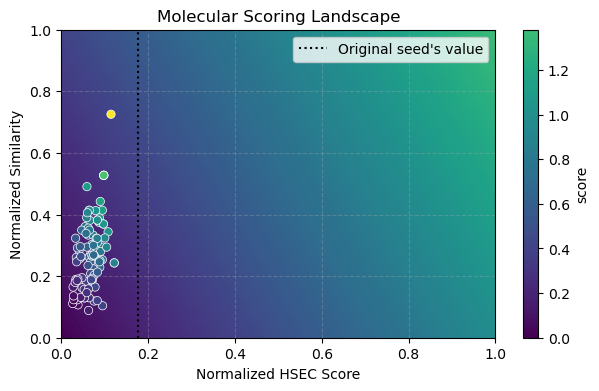

In [12]:
# get normalized values of molecules from scorer
x_scores = results.norm_qsar_hsec_scores   ## Already normalized 0-1
y_scores = results.norm_similarity_scores  ## Already normalized 0-1

# set color for scatter
color = -1*results.combined_scores


# Create a uniform grid from 0 to 1
deltas = np.linspace(0, 1, 100)
Xgrid, Ygrid = np.meshgrid(deltas, deltas)

# Calculate scores across the entire grid
grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid*scorer.hsec_max + scorer.hsec_min)

# Plot everything
plt.figure(figsize=(7, 4))

# Plot contour background (0-1 range)
contour = plt.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
plt.colorbar(label='score', ticks=np.linspace(0,2,11))

# Plot reference line for seed value
plt.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Original seed's value")

# Plot data points (already normalized)
plt.scatter(x_scores, y_scores, c=color, edgecolor='white', linewidths=0.5, cmap='viridis')

plt.xlabel("Normalized HSEC Score") 
plt.ylabel("Normalized Similarity")
plt.title("Molecular Scoring Landscape")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.xlim(0, 1)
plt.ylim(0, 1)



## Controlled Generation with CMA-ES and the custom oracle

### Generate hidden state encoding for the imatinib seed to initialize CMA-ES

To start the CMA-ES optimization process, we first seed the optimizer with the hidden state encoding for our imatinib seed molecule using the `/hidden` endpoint.

In [13]:
# First calculate a hidden state representation of our seed, imatinib.
headers = {
    'accept': 'application/json',
    'Content-Type': 'application/json'
}
data = {
    "sequences": [m1],
}

# Get the response from the server
response = requests.post(hidden_url, headers=headers, json=data)
imatinib_hidden = np.squeeze(np.array(response.json()["hiddens"]))

# We can use this seed hidden state as a starting point for our CMA-ES optimizer
popsize = sampling_summary['valid_smiles']
sigma=1.0

# Initialize with zeros or the hidden state encoding for imatinib
#optimizer = cma.CMAEvolutionStrategy(np.zeros(imatinib_hidden.size, dtype=np.float32), sigma, {'popsize': popsize})
optimizer = cma.CMAEvolutionStrategy(imatinib_hidden, sigma, {'popsize': popsize})

(50_w,100)-aCMA-ES (mu_w=27.0,w_1=8%) in dimension 512 (seed=956861, Thu Mar 13 08:22:04 2025)


Now that we've initialized the CMA-ES optimizer, we can generate and decode an initial set of trial encodings using the `/decode` endpoint.

In [14]:
# Generate and decode a set of initial trial encodings with CMA-ESecode trial encodings

trial_encodings=optimizer.ask(popsize)

headers = {
    'accept': 'application/json',
    'Content-Type': 'application/json'
}
hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
hiddens_json = {"hiddens":hiddens_array.tolist(),
                "mask": [[True] for i in range(hiddens_array.shape[0])]}


response = requests.post(decode_url, headers=headers, json=hiddens_json)
molecules = list(dict.fromkeys(response.json()['generated']))

We can then calculate the scores for this trial population and plot the results in our search space.

In [15]:
# score current draw
results = scorer.score(molecules, reference_smiles=m1)

# Sampling summary
print(len(molecules))

#~now scoring~#
#~Done scoring~#
99


In [16]:
# SET MANUALLY
metric='norm_qsar_hsec_scores' # 'qsar_hsec_scores'

# Extract scores based on the chosen metric and convert to numpy arrays if needed
x_scores = np.array(getattr(results, metric))
y_scores = np.array(results.similarity_scores)


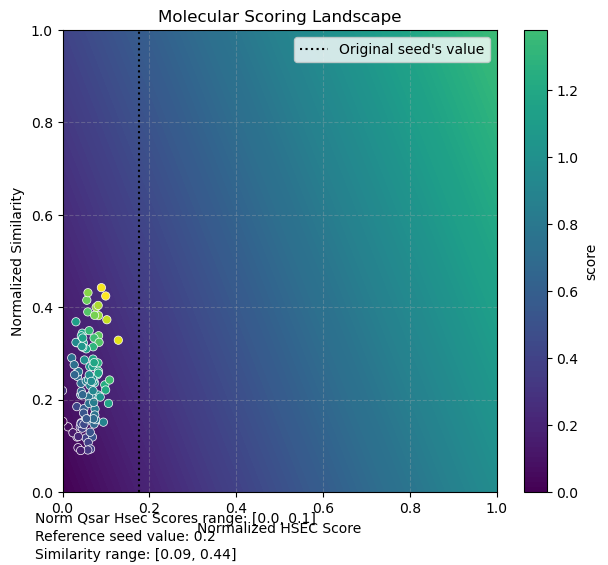

In [17]:
# Get combined scores for point coloring
color_values = -1 * np.array(results.combined_scores)

# Create a uniform grid from 0 to 1
deltas = np.linspace(0, 1, 100)
Xgrid, Ygrid = np.meshgrid(deltas, deltas)

# Calculate scores across the entire grid
grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid*scorer.hsec_max + scorer.hsec_min)

# Plot everything
plt.figure(figsize=(7, 6))

# Plot contour background (0-1 range)
contour = plt.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
plt.colorbar(label='score', ticks=np.linspace(0,2,11))

# Plot reference line for seed value
plt.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Original seed's value")

# Plot data points (already normalized)
plt.scatter(x_scores, y_scores, c=color_values, edgecolor='white', linewidths=0.5, cmap='viridis')

plt.xlabel("Normalized HSEC Score") 
plt.ylabel("Normalized Similarity")
plt.title("Molecular Scoring Landscape")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.xlim(0, 1)
plt.ylim(0, 1)

# Add annotations showing ranges and reference value
plt.annotate(f"{metric.replace('_', ' ').title()} range: [{np.min(x_scores):.1f}, {np.max(x_scores):.1f}]",
            xy=(0.05, 0.07), xycoords='figure fraction')

# Add annotation for seed value
plt.annotate(f"Reference seed value: {seed_score:.1f}", 
            xy=(0.05, 0.04), xycoords='figure fraction')

plt.annotate(f"Similarity range: [{np.min(y_scores):.2f}, {np.max(y_scores):.2f}]",
            xy=(0.05, 0.01), xycoords='figure fraction')
    
plt.show()


### Iterative optimization with CMA-ES and the custom oracle function
Now that we have our starting population, we can iteratively optimize using the CMA-ES strategy:

1. Generate a new set of trial encodings
2. Decode and calculate scores
3. Generate a new set of hidden state representations for valid trial candidates
4. Update the CMA-ES optimizer with the current combination of scores and hidden state representations

Note that through the CMA-ES optimization loop, we will occasionally encounter invalid SMILES depending on the search parameters.  We will stop the CMA-ES optimization loop if we have reduced our starting population by half.

In [18]:
popsize

100

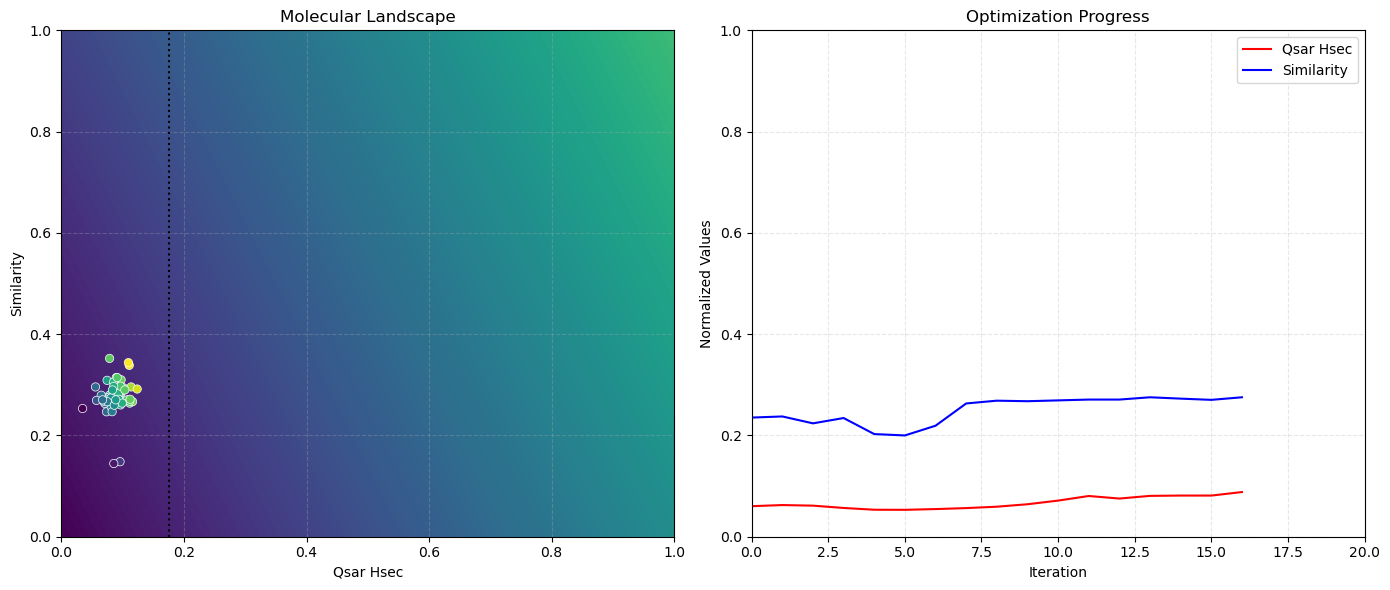

<Figure size 640x480 with 0 Axes>

Iter 16/20: Pop=56, Qsar Hsec=0.09, Sim=0.28
#~now scoring~#
#~Done scoring~#
Stopping at minimum population size 49

Optimization complete!


In [19]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# Set the normalized metric to use
metric = 'norm_qsar_hsec_scores'
raw_metric = metric.replace('norm_', '')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Initialize tracking lists for median values
med_scores = [np.median(np.array(getattr(results, metric)))]
med_sims = [np.median(np.array(results.norm_similarity_scores))]

# Set parameters for optimization
minpopsize = popsize/2
n_steps = 20

for i in range(n_steps):
    # Ask for trial encodings
    trial_encodings = optimizer.ask(popsize)
    # Decode to molecules
    hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
    hiddens_json = {"hiddens": hiddens_array.tolist(), "mask": [[True] for _ in range(hiddens_array.shape[0])]}
    response = requests.post(decode_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=hiddens_json)
    # Process valid molecules
    molecules = list(dict.fromkeys(response.json()['generated']))
    valid_smiles = [m for m in molecules if Chem.MolFromSmiles(m) is not None]
    # Get encodings for valid SMILES
    data = {"sequences": valid_smiles}
    response = requests.post(hidden_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=data)
    hiddens_array = np.squeeze(np.array(response.json()["hiddens"]))
    
    # Score molecules
    results = scorer.score(valid_smiles, reference_smiles=m1)
    popsize = len(results.combined_scores)
    
    # Check population size
    if popsize <= minpopsize:
        print(f"Stopping at minimum population size {popsize}")
        break
    
    # Update optimizer
    optimizer.tell(np.squeeze(np.array(hiddens_array)), results.combined_scores)
    
    # Extract normalized scores
    x_scores = np.array(getattr(results, metric))
    y_scores = np.array(results.norm_similarity_scores)
    color_values = -1 * np.array(results.combined_scores)

    ##### plots
    # Clear plots
    ax1.clear()
    ax2.clear()
    clear_output(wait=True)
    
    # Create grid for the background
    deltas = np.linspace(0, 1, 100)
    Xgrid, Ygrid = np.meshgrid(deltas, deltas)
    
    # calc grid scores ######## !!! ADAPT when change metric
    #grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid)
    grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid*scorer.hsec_max + scorer.hsec_min)
    
    # Plot 1: Molecular landscape
    contour = ax1.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
    # Plot reference line for seed value (assuming it's already normalized)
    ax1.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Seed")
    
    # Plot data points
    scatter = ax1.scatter(x_scores, y_scores, c=color_values, edgecolor='white', linewidths=0.5, cmap='viridis')
    # Set labels and appearance
    metric_label = metric.replace('norm_', '').replace('_scores', '').replace('_', ' ').title()
    ax1.set_xlabel(f"{metric_label}")
    ax1.set_ylabel("Similarity")
    ax1.set_title("Molecular Landscape")
    ax1.grid(alpha=0.3, linestyle='--')
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    # Update tracking lists
    med_scores.append(np.median(x_scores))
    med_sims.append(np.median(y_scores))
    
    # Plot 2: Progress tracking
    ax2.plot(med_scores, color='red', label=metric_label)
    ax2.plot(med_sims, color='blue', label='Similarity')
    ax2.set_ylabel("Normalized Values")
    ax2.set_xlabel("Iteration")
    ax2.set_xlim(0, n_steps)
    ax2.set_ylim(0, 1)
    ax2.grid(alpha=0.3, linestyle='--')
    ax2.legend()
    ax2.set_title("Optimization Progress")
    
    # Display figure
    plt.tight_layout()
    display(fig)
    plt.pause(0.1)
    
    print(f"Iter {i+1}/{n_steps}: Pop={popsize}, {metric_label}={med_scores[-1]:.2f}, Sim={med_sims[-1]:.2f}")

print("\nOptimization complete!")

## Viewing the resulting optimized molecules.

In [20]:
len(valid_smiles)

49

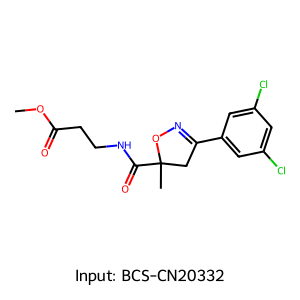

In [21]:
input_mol = Chem.MolFromSmiles(m1)

Draw.MolToImage(input_mol, legend=str(f"Input: {m1_name}" ), subImgSize=(350,360))

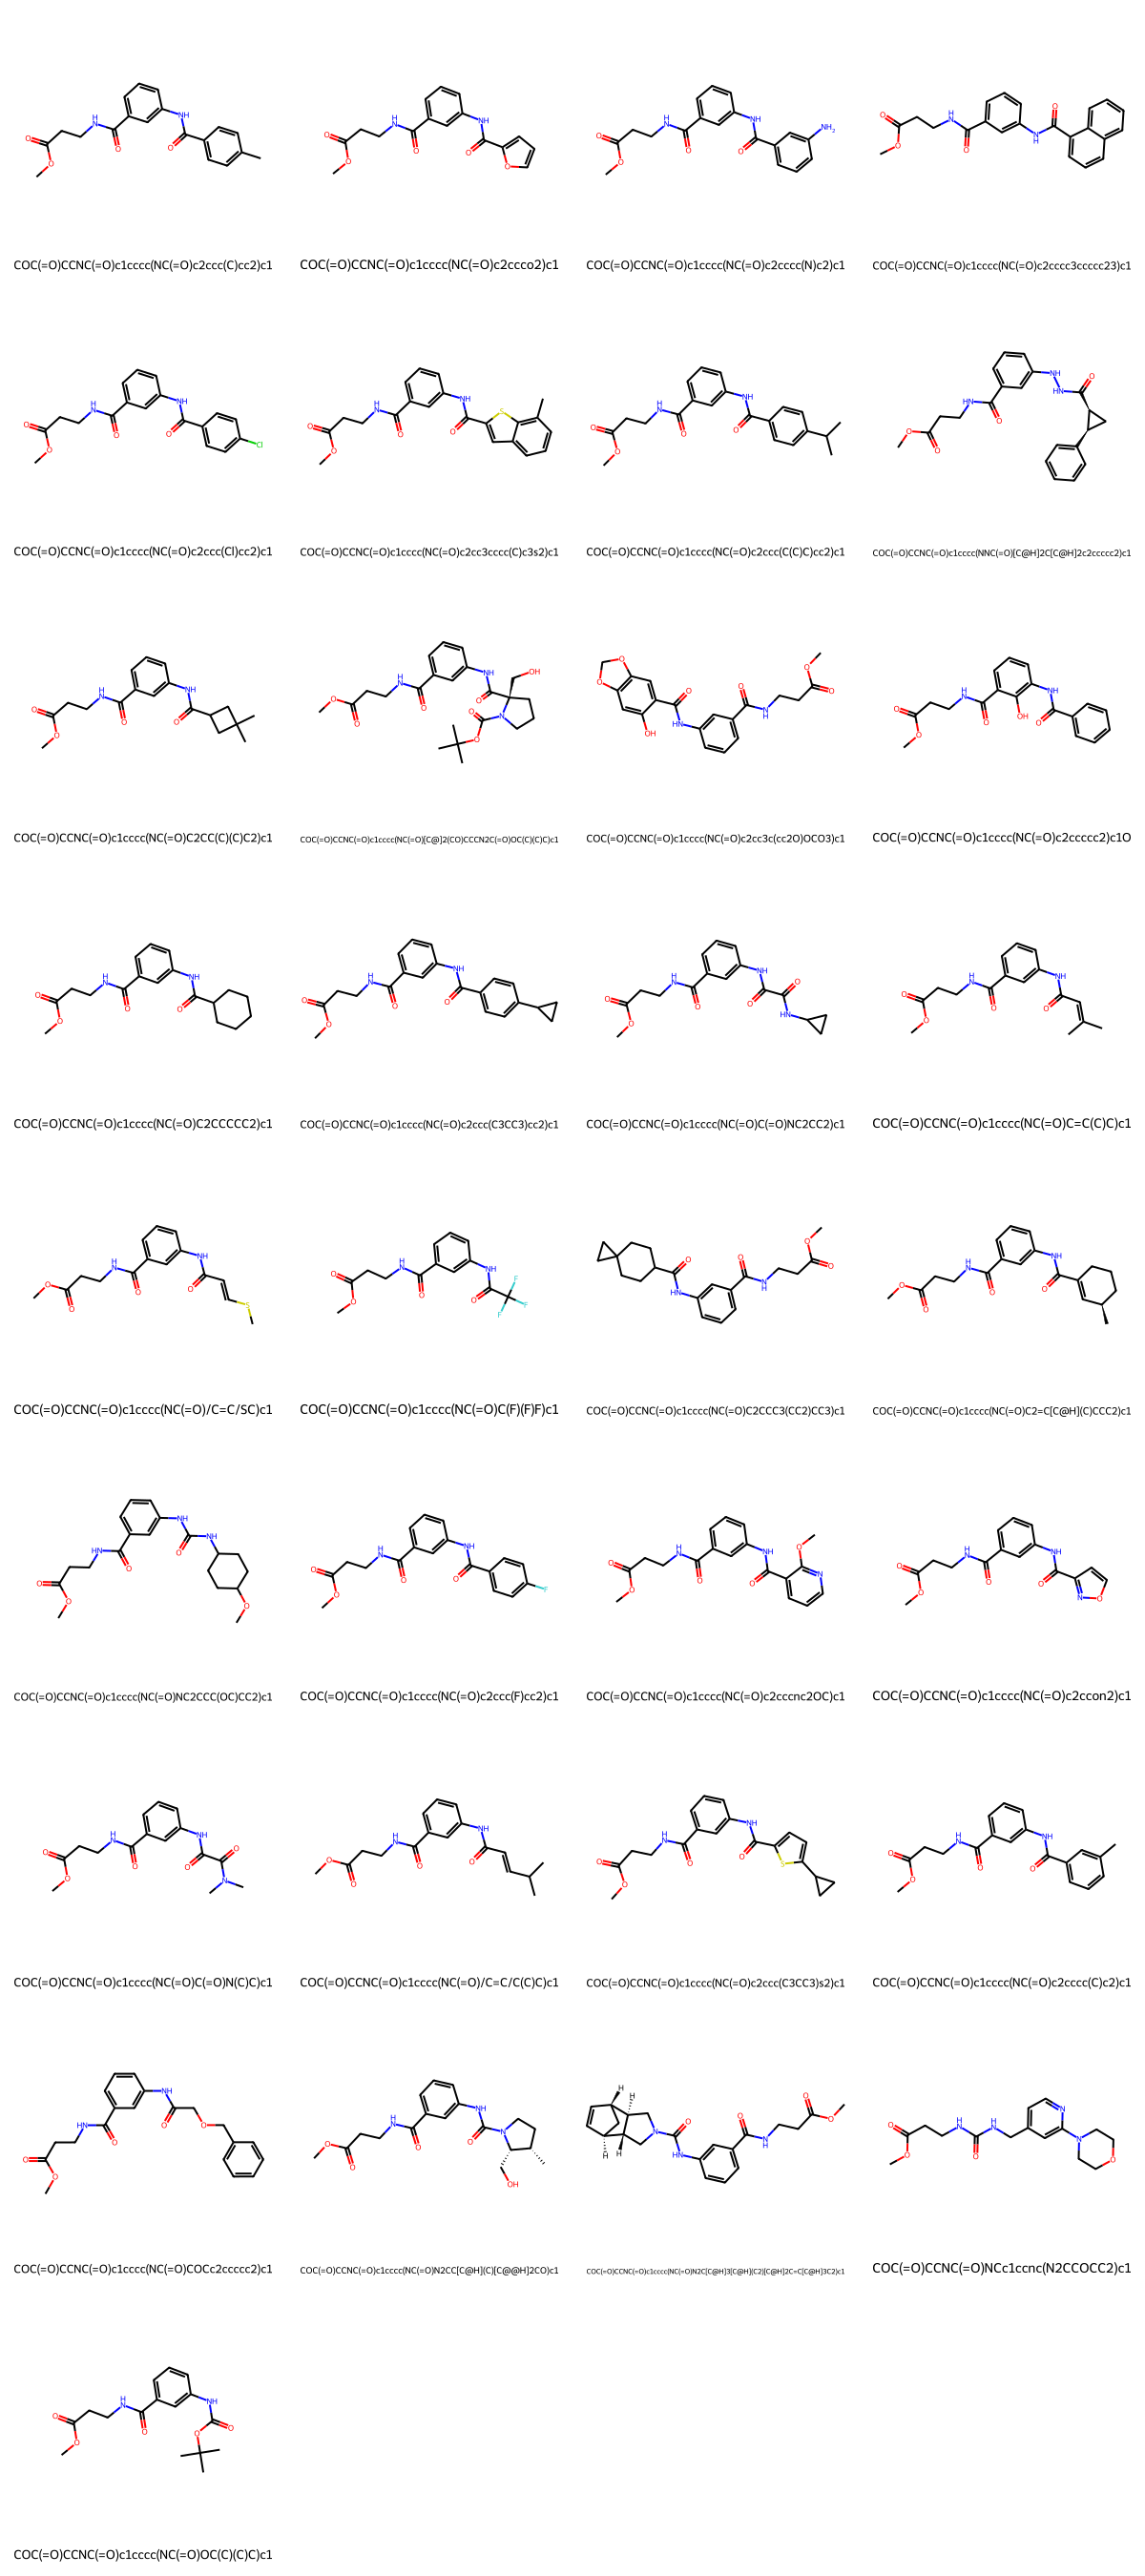

In [22]:
Draw.MolsToGridImage([Chem.MolFromSmiles(smile, sanitize=False) for smile in valid_smiles[:33]],
                     legends=molecules, molsPerRow=4, subImgSize=(300, 300))

In [23]:
import pandas as pd
df = pd.DataFrame({"valid_smiles": valid_smiles })

In [24]:
import helper
df['LogP'] = df['valid_smiles'].apply(helper.calculate_logp)
df['QED'] = df['valid_smiles'].apply(helper.calculate_qed)

In [25]:
df.sort_values(["QED"], inplace=True, ascending=False)
df.head(10)

,valid_smiles,LogP,QED
32,COC(=O)CCNC(=O)c1cccc(NC(=O)OC(C)(C)C)c1,2.32650,0.811491
17,COC(=O)CCNC(=O)c1cccc(NC(=O)C(F)(F)F)c1,1.48030,0.805514
34,COC(=O)CCNC(=O)c1cccc(NC(=O)N2CCC(C)CC2)c1,2.24330,0.799810
43,COC(=O)CCNC(=O)c1cccc(NC(=O)c2ccccc2)c1,2.23180,0.797371
1,COC(=O)CCNC(=O)c1cccc(NC(=O)c2ccco2)c1,1.82480,0.792306
0,COC(=O)CCNC(=O)c1cccc(NC(=O)c2ccc(C)cc2)c1,2.54022,0.791604
27,COC(=O)CCNC(=O)c1cccc(NC(=O)c2cccc(C)c2)c1,2.54022,0.791604
21,COC(=O)CCNC(=O)c1cccc(NC(=O)c2ccc(F)cc2)c1,2.37090,0.788144
12,COC(=O)CCNC(=O)c1cccc(NC(=O)C2CCCCC2)c1,2.49830,0.783984
8,COC(=O)CCNC(=O)c1cccc(NC(=O)C2CC(C)(C)C2)c1,2.35420,0.783292


In [26]:
df.to_csv('../../data/interim/molmim/guided/molmmim_QSAR_HSEC_BCS-CN20332_b2_n200.csv', index=False, sep=';', header=True) 
#../../data/interim/molmmim_BCS-CN20332_LogP_sim03_100p_100m
#../../data/interim/XXX.csv

## Second Seed